# 模块6：卖家分层与健康度

**业务问题：** GMV 和问题是否集中在少数卖家？应如何分层管理卖家？模块3 遗留的"卖家超时 → 差评"是等待造成的，还是卖家质量造成的？

**数据：** `dws_seller`（2,945 个卖家，一行一个卖家）、`ads_m6_seller_tier`（分层结果）、`dws_order_fulfillment`

**口径：** 规模指标含多卖家订单，体验指标只用单卖家订单（D-029）；分层规则见 D-030

**结论：** 详见 `docs/stage_summaries/stage_2.md` 模块6。

In [14]:
from olist_utils import run_query, set_style, COLORS
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
set_style()

## 6.1 GMV 集中度

集中度：头部卖家贡献了多少 GMV； 方法：帕累托曲线

In [15]:
sql_pareto = """
WITH ranked AS (
    SELECT seller_id, gmv,
           ROW_NUMBER() OVER (ORDER BY gmv DESC, seller_id) AS gmv_rank,
           COUNT(*)     OVER ()                             AS n_sellers,
           SUM(gmv)     OVER (ORDER BY gmv DESC, seller_id) AS cum_gmv,
           SUM(gmv)     OVER ()                             AS total_gmv
    FROM dws_seller
)
SELECT gmv_rank,
       gmv,
       ROUND(gmv_rank / n_sellers, 4) AS seller_share,
       ROUND(cum_gmv / total_gmv, 4)  AS gmv_share
FROM ranked
ORDER BY gmv_rank;
"""
df_pareto = run_query(sql_pareto)
df_pareto[["seller_share", "gmv_share"]] = df_pareto[["seller_share", "gmv_share"]].astype(float)

print(len(df_pareto), df_pareto["gmv_share"].iloc[-1])          
print(df_pareto.loc[df_pareto["gmv_rank"] == 29, "gmv_share"])   
print("卖家 GMV 中位数：", df_pareto["gmv"].median())

2945 1.0
28    0.2552
Name: gmv_share, dtype: float64
卖家 GMV 中位数： 849.7


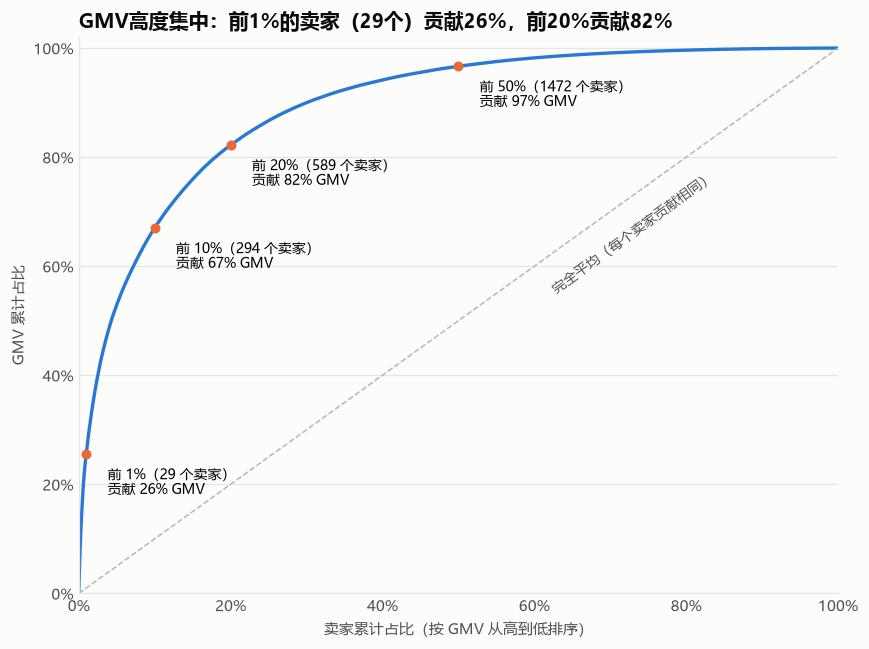

In [16]:
fig, ax = plt.subplots(figsize=(8, 6))

# 曲线从原点出发：在最前面补一个 (0, 0)
x = pd.concat([pd.Series([0.0]), df_pareto["seller_share"]])
y = pd.concat([pd.Series([0.0]), df_pareto["gmv_share"]])
ax.plot(x, y, color=COLORS["blue"], linewidth=2.2)

# 对角线：如果每个卖家贡献完全相同，曲线就是这条线
ax.plot([0, 1], [0, 1], color=COLORS["gray"], linestyle="--", linewidth=1)
ax.text(0.62, 0.55, "完全平均（每个卖家贡献相同）",
        color=COLORS["text_secondary"], fontsize=9, rotation=36)

# 标注前 1% / 10% / 20% / 50%
for k in [0.01, 0.10, 0.20, 0.5]:
    r = df_pareto[df_pareto["seller_share"] <= k + 1e-9].iloc[-1]
    ax.scatter(r["seller_share"], r["gmv_share"], color=COLORS["orange"], zorder=3, s=30)
    ax.annotate(f"前 {k:.0%}（{int(r['gmv_rank'])} 个卖家）\n贡献 {r['gmv_share']:.0%} GMV",
                (r["seller_share"], r["gmv_share"]),
                xytext=(14, -26), textcoords="offset points", fontsize=9)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("卖家累计占比（按 GMV 从高到低排序）")
ax.set_ylabel("GMV 累计占比")
ax.set_title("GMV高度集中：前1%的卖家（29个）贡献26%，前20%贡献82%", loc="left")

fig.tight_layout()
fig.savefig("../docs/figures/m6_pareto.png", dpi=150, bbox_inches="tight")
plt.show()

## 6.2 卖家分层

按健康度给头部卖家(前20%)分层（两个指标: 卖家发货超时率、未延误订单差评率）

In [17]:
sql_tier = """
SELECT *
FROM ads_m6_seller_tier
WHERE tier <> '样本不足'
"""
df_tier = run_query(sql_tier)
num_cols = ["gmv", "ot_bad_rate", "platform_ot_bad", "seller_late_rate", "platform_seller_late"]
df_tier[num_cols] = df_tier[num_cols].astype(float)
TOTAL_GMV = 13179777.95                   # 全平台 GMV，用于计算占比
print(len(df_tier))                       # 核对：575
df_tier["problem_type"].value_counts()

575


problem_type
健康      451
时效问题     76
体验问题     25
双重问题     23
Name: count, dtype: int64

In [18]:
# 各类问题卖家（头部）比平台平均多造成了多少差评
sql_harm = """
SELECT problem_type,
       COUNT(*)                                                    AS sellers,
       SUM(gmv)                                                    AS gmv,
       SUM(n_ot_bad - n_ot_reviewed * platform_ot_bad)             AS excess_bad,        -- 直接多出的差评
       SUM(n_seller_late - n_ship_orders * platform_seller_late)   AS excess_ship_late   -- 多出的发货超时单
FROM ads_m6_seller_tier
WHERE is_head = 1
  AND problem_type IS NOT NULL      -- 排除头部中样本不足的卖家
GROUP BY problem_type
"""

# 两个"增加幅度"：从数据里现算，不写死
sql_lift = """
SELECT AVG(CASE WHEN is_seller_late = 1 THEN is_late END)
     - AVG(CASE WHEN is_seller_late = 0 THEN is_late END)    AS late_lift,   -- 超时让延误风险增加多少
       AVG(CASE WHEN is_late = 1 THEN is_bad_review END)
     - AVG(CASE WHEN is_late = 0 THEN is_bad_review END)     AS bad_lift     -- 延误让差评率增加多少
FROM dws_order_fulfillment
WHERE is_seller_late IS NOT NULL
"""

df_harm = run_query(sql_harm)
lift    = run_query(sql_lift).astype(float).iloc[0]

num = ["gmv", "excess_bad", "excess_ship_late"]
df_harm[num] = df_harm[num].astype(float)

df_harm["gmv_share"]      = df_harm["gmv"] / TOTAL_GMV
# 间接损害：多出的超时单 × 延误风险增幅 × 差评率增幅（粗略估算）
df_harm["indirect_bad"]   = df_harm["excess_ship_late"].clip(lower=0) * lift["late_lift"] * lift["bad_lift"]
# 总损害：负数（比平均好）不抵消其他损害，截到 0
df_harm["total_bad"]      = df_harm["excess_bad"].clip(lower=0) + df_harm["indirect_bad"]
df_harm["bad_per_seller"] = df_harm["total_bad"] / df_harm["sellers"]

print(f"发货超时 → 延误风险 +{lift['late_lift']:.1%}；延误 → 差评率 +{lift['bad_lift']:.1%}")
(df_harm.sort_values("total_bad", ascending=False)
        [["problem_type", "sellers", "gmv_share", "excess_bad", "excess_ship_late",
          "indirect_bad", "total_bad", "bad_per_seller"]]
        .round({"gmv_share": 3, "excess_bad": 0, "excess_ship_late": 0,
                "indirect_bad": 0, "total_bad": 0, "bad_per_seller": 1}))

发货超时 → 延误风险 +15.8%；延误 → 差评率 +53.7%


,problem_type,sellers,gmv_share,excess_bad,excess_ship_late,indirect_bad,total_bad,bad_per_seller
3,双重问题,19,0.050,424.0,775.0,66.0,489.0,25.8
2,体验问题,21,0.062,435.0,-267.0,0.0,435.0,20.7
1,时效问题,59,0.090,-26.0,1341.0,113.0,113.0,1.9
0,健康,328,0.511,-632.0,-2127.0,0.0,0.0,0.0


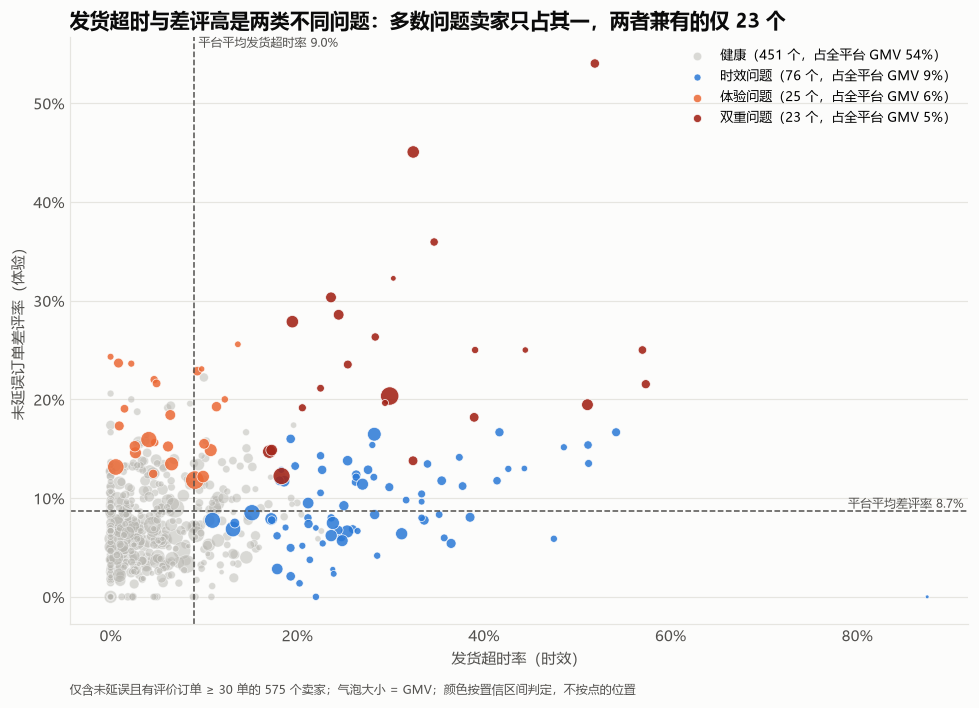

In [19]:
p0 = df_tier["platform_ot_bad"].iloc[0]          # 平台未延误差评率
q0 = df_tier["platform_seller_late"].iloc[0]     # 平台发货超时率

type_style = {                                   # 类型: (颜色, 透明度)
    "健康":     (COLORS["gray"],   0.5),
    "时效问题": (COLORS["blue"],   0.85),
    "体验问题": (COLORS["orange"], 0.85),
    "双重问题": ("#a3271b",        0.9),         # 深红：两项都有问题，最需要关注
}

fig, ax = plt.subplots(figsize=(9, 6.5))
for t, (color, alpha) in type_style.items():
    d = df_tier[df_tier["problem_type"] == t]
    ax.scatter(d["seller_late_rate"], d["ot_bad_rate"], s=np.sqrt(d["gmv"]) / 3,
               color=color, alpha=alpha, edgecolors="white", linewidths=0.5,
               label=f"{t}（{len(d)} 个，占全平台 GMV {d['gmv'].sum() / TOTAL_GMV:.0%}）")

ax.axvline(q0, color=COLORS["text_secondary"], linestyle="--", linewidth=1)
ax.axhline(p0, color=COLORS["text_secondary"], linestyle="--", linewidth=1)
ax.text(q0, 1.0, f" 平台平均发货超时率 {q0:.1%}", transform=ax.get_xaxis_transform(),
        fontsize=8, color=COLORS["text_secondary"], va="top")
ax.text(1.0, p0, f"平台平均差评率 {p0:.1%} ", transform=ax.get_yaxis_transform(),
        fontsize=8, color=COLORS["text_secondary"], ha="right", va="bottom")

ax.xaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0))
ax.set_xlabel("发货超时率（时效）")
ax.set_ylabel("未延误订单差评率（体验）")
ax.legend(frameon=False, loc="upper right", fontsize=8.5, markerscale=0.6)
ax.set_title("发货超时与差评高是两类不同问题：多数问题卖家只占其一，两者兼有的仅 23 个", loc="left")
ax.text(0.0, -0.12,
        f"仅含未延误且有评价订单 ≥ 30 单的 {len(df_tier)} 个卖家；气泡大小 = GMV；颜色按置信区间判定，不按点的位置",
        transform=ax.transAxes, fontsize=8, color=COLORS["text_secondary"])

fig.tight_layout()
fig.savefig("../docs/figures/m6_seller_tier.png", dpi=150, bbox_inches="tight")
plt.show()

In [20]:
cols = ["gmv_rank", "gmv", "seller_state", "main_category", "problem_type",
        "n_ot_reviewed", "ot_bad_rate", "seller_late_rate"]
df_tier[df_tier["problem_type"] != "健康"].sort_values("gmv", ascending=False)[cols].head(10)

,gmv_rank,gmv,seller_state,main_category,problem_type,n_ot_reviewed,ot_bad_rate,seller_late_rate
6,3,196882.12,SP,bed_bath_table,体验问题,1489,0.1182,0.0903
360,5,186570.05,SP,office_furniture,双重问题,870,0.2034,0.2991
349,9,138208.56,SP,furniture_decor,双重问题,801,0.1223,0.1832
11,11,120702.83,SP,watches_gifts,体验问题,1680,0.1315,0.0056
395,13,112436.18,SP,watches_gifts,时效问题,481,0.0852,0.1515
9,14,111126.73,SP,baby,体验问题,295,0.1593,0.0410
377,16,106655.71,SP,garden_tools,时效问题,1238,0.0775,0.1092
381,19,93407.40,SP,stationery,时效问题,976,0.0686,0.1312
16,25,62081.46,SP,furniture_decor,体验问题,616,0.1347,0.0654
368,26,58991.80,SC,health_beauty,时效问题,85,0.1647,0.2826


## 6.3 卖家内部对比

卖家内部对比: 

发现的问题: 最终准时的订单里，卖家的发货超时的差评率比准时的高4.9个百分点；因此我们要探索到底是等待效应导致，还是说发货慢的本来就是差的卖家，其对应的商品和服务也差。

In [21]:
#卖家内部对比
sql_within = """
SELECT seller_id,
       SUM(CASE WHEN is_seller_late = 1 THEN has_review    END) AS n_late_ship,
       SUM(CASE WHEN is_seller_late = 1 THEN is_bad_review END) AS bad_late_ship,
       SUM(CASE WHEN is_seller_late = 0 THEN has_review    END) AS n_ontime_ship,
       SUM(CASE WHEN is_seller_late = 0 THEN is_bad_review END) AS bad_ontime_ship
FROM dws_order_fulfillment
WHERE is_late = 0                                  -- 只看最终准时送达的订单（3.3 的 ① vs ③）
  AND is_seller_late IS NOT NULL
GROUP BY seller_id
HAVING n_late_ship >= 1 AND n_ontime_ship >= 1     -- 两种发货情况都有评价的卖家
"""
df_w = run_query(sql_within).set_index("seller_id").astype(float)

df_w["p_late"]   = df_w["bad_late_ship"]   / df_w["n_late_ship"]     # 该卖家超时发货的差评率
df_w["p_ontime"] = df_w["bad_ontime_ship"] / df_w["n_ontime_ship"]   # 该卖家准时发货的差评率
df_w["w"]        = (df_w["n_late_ship"] * df_w["n_ontime_ship"]
                    / (df_w["n_late_ship"] + df_w["n_ontime_ship"])) # 调和权重：两组都多，权重才大

def within_diff(d):
    """每个卖家内部的差距，按调和权重加权平均"""
    return np.average(d["p_late"] - d["p_ontime"], weights=d["w"])

# 对照：同一批卖家，不分卖家直接合并比较（仍然混入了卖家质量的差异）
pooled_diff = (df_w["bad_late_ship"].sum() / df_w["n_late_ship"].sum()
               - df_w["bad_ontime_ship"].sum() / df_w["n_ontime_ship"].sum())

print(f"卖家数：{len(df_w)}")                                  # 核对：1074
print(f"混合比较（同一批卖家，直接合并）：{pooled_diff:+.2%}")
print(f"卖家内部比较（加权平均）：      {within_diff(df_w):+.2%}")

卖家数：1074
混合比较（同一批卖家，直接合并）：+4.58%
卖家内部比较（加权平均）：      +2.76%


In [22]:
#Bootstrap 置信区间
rng  = np.random.default_rng(42)     # 固定随机种子，保证每次运行结果一样（可复现）
boot = []
for _ in range(2000):
    sample = df_w.sample(n=len(df_w), replace=True, random_state=rng)   # 有放回地抽卖家
    boot.append(within_diff(sample))

lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"卖家内部差异 95% 置信区间：{lo:+.2%} ~ {hi:+.2%}")

卖家内部差异 95% 置信区间：+1.82% ~ +3.74%


## 6.4 敏感性分析

敏感性分析：

为验证结论的稳健性，分别调整样本门槛（20/30/50 单）、头部范围（前 10%/20%/30%）和置信水平（90%/95%/99%），共 7 种情景；卖家内部对比另外调整每组最少评价数（1/3/5 条）。主口径一行必须与 6.2 的 SQL 结果一致，以验证 Python 版规则没有写错。

In [23]:
#读取原始个数，定义分层和汇总函数
TOTAL_GMV = 13179777.95

sql_base = """
SELECT seller_id, gmv, gmv_rank,
       n_ot_reviewed, n_ot_bad, platform_ot_bad,
       n_ship_orders, n_seller_late, platform_seller_late
FROM ads_m6_seller_tier
"""
base = run_query(sql_base).set_index("seller_id").astype(float)
p0 = base["platform_ot_bad"].iloc[0]          # 平台未延误差评率
q0 = base["platform_seller_late"].iloc[0]     # 平台发货超时率

sql_lift = """
SELECT AVG(CASE WHEN is_seller_late = 1 THEN is_late END)
     - AVG(CASE WHEN is_seller_late = 0 THEN is_late END)    AS late_lift,
       AVG(CASE WHEN is_late = 1 THEN is_bad_review END)
     - AVG(CASE WHEN is_late = 0 THEN is_bad_review END)     AS bad_lift
FROM dws_order_fulfillment
WHERE is_seller_late IS NOT NULL
"""
lift = run_query(sql_lift).astype(float).iloc[0]


def classify(min_n=30, head_pct=0.20, z=1.96):
    """用 Python 重写 D-030 的分层规则，三个设定做成参数；默认值 = 主口径"""
    d = base.copy()
    p = d["n_ot_bad"] / d["n_ot_reviewed"]          # 未延误差评率
    q = d["n_seller_late"] / d["n_ship_orders"]     # 发货超时率
    exp_bad  = (p - z * np.sqrt(p * (1 - p) / d["n_ot_reviewed"])) > p0   # 置信区间下限 > 平台平均
    ship_bad = (q - z * np.sqrt(q * (1 - q) / d["n_ship_orders"]))  > q0
    d["problem_type"] = np.select([exp_bad & ship_bad, exp_bad, ship_bad],
                                  ["双重问题", "体验问题", "时效问题"], "健康")
    d.loc[d["n_ot_reviewed"] < min_n, "problem_type"] = "样本不足"
    d["is_head"] = d["gmv_rank"] <= head_pct * len(d)
    return d


def summarize(d):
    """算出结论 ①②③ 要看的数字（只看头部、样本充足的卖家）"""
    h = d[d["is_head"] & (d["problem_type"] != "样本不足")]
    # 和 6.2 损害分析口径一致：先按类型汇总"多出的部分"，再把负数截到 0
    h = h.assign(excess_bad  = h["n_ot_bad"]      - h["n_ot_reviewed"] * p0,
                 excess_ship = h["n_seller_late"] - h["n_ship_orders"] * q0)
    g = h.groupby("problem_type").agg(n=("gmv", "size"), gmv=("gmv", "sum"),
                                      excess_bad=("excess_bad", "sum"),
                                      excess_ship=("excess_ship", "sum"))
    g["harm"] = (g["excess_bad"].clip(lower=0)
                 + g["excess_ship"].clip(lower=0) * lift["late_lift"] * lift["bad_lift"])
    problem = g.index != "健康"

    out = {f"{t}_个数": int(g["n"].get(t, 0)) for t in ["时效问题", "体验问题", "双重问题"]}
    out["问题卖家GMV占比"]  = g.loc[problem, "gmv"].sum() / TOTAL_GMV                 # 结论 ①
    out["双重占问题卖家比"] = g["n"].get("双重问题", 0) / g.loc[problem, "n"].sum()    # 结论 ②
    for t in ["双重问题", "体验问题", "时效问题"]:                                      # 结论 ③
        out[f"每卖家损害_{t[:2]}"] = g["harm"].get(t, np.nan) / g["n"].get(t, np.nan)
    return out

In [24]:
#7种情景
scenarios = [
    ("主口径",       dict()),
    ("样本门槛 20",  dict(min_n=20)),
    ("样本门槛 50",  dict(min_n=50)),
    ("头部 前10%",   dict(head_pct=0.10)),
    ("头部 前30%",   dict(head_pct=0.30)),
    ("置信水平 90%", dict(z=1.645)),
    ("置信水平 99%", dict(z=2.576)),
]

rows = []
for name, kw in scenarios:
    r = summarize(classify(**kw))
    r["情景"] = name
    rows.append(r)

df_sens = pd.DataFrame(rows).set_index("情景")
df_sens.round({"问题卖家GMV占比": 3, "双重占问题卖家比": 2,
               "每卖家损害_双重": 1, "每卖家损害_体验": 1, "每卖家损害_时效": 1})

,时效问题_个数,体验问题_个数,双重问题_个数,问题卖家GMV占比,双重占问题卖家比,每卖家损害_双重,每卖家损害_体验,每卖家损害_时效
情景,,,,,,,,
主口径,59,21,19,0.202,0.19,25.8,20.7,1.9
样本门槛 20,64,21,19,0.204,0.18,25.8,20.7,1.8
样本门槛 50,48,20,19,0.193,0.22,25.8,21.5,2.1
头部 前10%,34,16,14,0.183,0.22,29.8,23.2,2.2
头部 前30%,74,25,22,0.208,0.18,23.3,18.9,1.8
置信水平 90%,63,31,20,0.218,0.18,24.9,16.1,1.8
置信水平 99%,52,14,12,0.170,0.15,34.5,25.7,3.0


In [25]:
#卖家内部对比的敏感性
rows = []
for k in [1, 3, 5]:
    d = df_w[(df_w["n_late_ship"] >= k) & (df_w["n_ontime_ship"] >= k)]   # 两组都至少 k 条评价
    rng  = np.random.default_rng(42)
    boot = [within_diff(d.sample(n=len(d), replace=True, random_state=rng)) for _ in range(2000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    rows.append({"每组至少评价数": k, "卖家数": len(d),
                 "卖家内部差异": within_diff(d), "CI下限": lo, "CI上限": hi})

pd.DataFrame(rows).round(4)

,每组至少评价数,卖家数,卖家内部差异,CI下限,CI上限
0,1,1074,0.0276,0.0182,0.0374
1,3,451,0.0292,0.0187,0.0405
2,5,290,0.0294,0.0183,0.0413


### 稳健性：只用单件订单重新分层

模块3（3.7）发现多件订单即使准时送达，差评率也明显更高。如果某些卖家多卖套装类商品，它们的差评率可能被多件订单拉高，被误判为"体验问题"。这里只用单件订单重新计算两个健康指标和平台基准，再按 D-030 的规则分层。

In [26]:
# 稳健性：只用单件订单重新分层（排除多件订单对差评率的影响，见模块3 3.7）
sql_single = """
SELECT t.seller_id, t.gmv, t.gmv_rank,
       SUM(CASE WHEN f.is_late = 0 THEN f.has_review    ELSE 0 END) AS n_ot_reviewed,
       SUM(CASE WHEN f.is_late = 0 THEN f.is_bad_review ELSE 0 END) AS n_ot_bad,
       COUNT(f.is_seller_late)                                     AS n_ship_orders,
       COALESCE(SUM(f.is_seller_late), 0)                          AS n_seller_late
FROM ads_m6_seller_tier t
LEFT JOIN dws_order_fulfillment f
       ON f.seller_id = t.seller_id AND f.n_items = 1
GROUP BY t.seller_id, t.gmv, t.gmv_rank
"""
single = run_query(sql_single).set_index("seller_id").astype(float)

# 用单件订单重新计算平台基准，再套用 D-030 的分层规则（与 6.4 的 classify 逻辑相同）
p0_s = single["n_ot_bad"].sum() / single["n_ot_reviewed"].sum()
q0_s = single["n_seller_late"].sum() / single["n_ship_orders"].sum()
p = single["n_ot_bad"] / single["n_ot_reviewed"]
q = single["n_seller_late"] / single["n_ship_orders"]
exp_bad  = (p - 1.96 * np.sqrt(p * (1 - p) / single["n_ot_reviewed"])) > p0_s
ship_bad = (q - 1.96 * np.sqrt(q * (1 - q) / single["n_ship_orders"]))  > q0_s
single["problem_type"] = np.select([exp_bad & ship_bad, exp_bad, ship_bad],
                                   ["双重问题", "体验问题", "时效问题"], "健康")
single.loc[single["n_ot_reviewed"] < 30, "problem_type"] = "样本不足"
single["is_head"] = single["gmv_rank"] <= 0.2 * len(single)

print(f"单件订单的平台基准：未延误差评率 {p0_s:.2%}，发货超时率 {q0_s:.2%}")
main = classify()                                   # 6.4 定义的函数，默认参数 = 主口径
head_main   = main[main["is_head"]]["problem_type"].value_counts()
head_single = single[single["is_head"]]["problem_type"].value_counts()
pd.DataFrame({"主口径（全部订单）": head_main, "只用单件订单": head_single}).fillna(0).astype(int)

单件订单的平台基准：未延误差评率 7.53%，发货超时率 8.77%


,主口径（全部订单）,只用单件订单
problem_type,,
健康,328,319
样本不足,162,172
时效问题,59,61
体验问题,21,21
双重问题,19,16


In [27]:
# 主口径判为"体验问题"或"双重问题"的头部卖家，用单件订单后有多少仍被判为有体验问题
main_exp = main[main["is_head"] & main["problem_type"].isin(["体验问题", "双重问题"])].index
still = single.loc[main_exp, "problem_type"].isin(["体验问题", "双重问题"])
print(f"主口径的体验/双重问题头部卖家 {len(main_exp)} 个，只用单件订单后仍有体验问题的 {still.sum()} 个（{still.mean():.0%}）")
single.loc[main_exp, "problem_type"].value_counts()

主口径的体验/双重问题头部卖家 40 个，只用单件订单后仍有体验问题的 34 个（85%）


problem_type
体验问题    19
双重问题    15
时效问题     4
样本不足     1
健康       1
Name: count, dtype: int64

**结论：** 只用单件订单重新分层后，主口径下 40 个体验 / 双重问题头部卖家中，有 34 个（85%）仍被判为有体验问题；4 个变为只有时效问题，2 个变为健康或样本不足。四类卖家的数量变化很小，**分层结论对多件订单不敏感**。